### 09 — Final System Evaluation

What this notebook does:

- load the completed multimodal system and all trained checkpoints
- evaluate U-Net lesion segmentation on the held-out test set
- evaluate benign/malignant classification performance
- plot the confusion matrix and ROC curve
- generate structured reports for all test cases
- evaluate report quality using BLEU, ROUGE-L, and METEOR
- perform basic classification and segmentation error analysis
- save per-case results and the final evaluation summary.


### 1. Imports and Project Setup


In [1]:
from pathlib import Path
import sys
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch

from transformers import AutoTokenizer, GPT2Tokenizer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from nltk.translate.bleu_score import (
    sentence_bleu,
    SmoothingFunction
)
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer

PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

IMAGE_DIR = RAW_DIR / "images"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

from src.unet import UNet
from src.image_encoder import EfficientNetEncoder
from src.clinical_encoder import ClinicalBERTEncoder
from src.fusion import CrossAttentionFusion
from src.classifier import MultimodalClassifier
from src.report_generator import MultimodalReportGenerator

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project root:", PROJECT_ROOT)
print("Images:", IMAGE_DIR.exists())
print("Models:", MODEL_DIR.exists())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


c:\Users\Akash\Desktop\Python\breast-ultrasound-fyp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: C:\Users\Akash\Desktop\Python\breast-ultrasound-fyp
Images: True
Models: True
Device: cuda
GPU: NVIDIA GeForce GTX 1650


### 2. Load the Test Set and Tokenizers

The held-out `test.csv` split is used for all final evaluations.

ClinicalBERT uses the same tokenizer as the classification pipeline. GPT-2 uses its EOS token for padding, and the custom `<END_REPORT>` token is restored before loading the report-generator checkpoint.


In [2]:
test_df = pd.read_csv(
    PROCESSED_DIR / "test.csv"
)

CLINICAL_MODEL_NAME = (
    "emilyalsentzer/Bio_ClinicalBERT"
)
GPT2_MODEL_NAME = "gpt2"

clinical_tokenizer = AutoTokenizer.from_pretrained(
    CLINICAL_MODEL_NAME
)

gpt2_tokenizer = GPT2Tokenizer.from_pretrained(
    GPT2_MODEL_NAME
)

gpt2_tokenizer.pad_token = (
    gpt2_tokenizer.eos_token
)

gpt2_tokenizer.add_special_tokens({
    "additional_special_tokens": [
        "<END_REPORT>"
    ]
})

END_REPORT_ID = (
    gpt2_tokenizer.convert_tokens_to_ids(
        "<END_REPORT>"
    )
)

print("Test cases:", len(test_df))


Test cases: 38


### 3. Load the Trained Models

The same configurations used by the integrated system are restored:

- U-Net lesion segmentation
- EfficientNet-B0 image encoder
- ClinicalBERT clinical encoder
- bidirectional cross-attention fusion
- multimodal benign/malignant classifier
- GPT-2 multimodal report generator.


In [3]:
# U-Net
segmentation_model = UNet().to(device)
segmentation_model.load_state_dict(
    torch.load(
        MODEL_DIR / "best_unet.pth",
        map_location=device
    )
)
segmentation_model.eval()

for parameter in segmentation_model.parameters():
    parameter.requires_grad = False


# Segmentation threshold
with open(
    MODEL_DIR / "segmentation_config.json",
    "r"
) as f:
    segmentation_config = json.load(f)

BEST_THRESHOLD = segmentation_config[
    "best_threshold"
]

print("Loaded BEST_THRESHOLD:", BEST_THRESHOLD)


# Multimodal classifier components
image_encoder = EfficientNetEncoder(
    output_dim=768
).to(device)

fusion_model = CrossAttentionFusion(
    embed_dim=768,
    num_heads=8,
    dropout=0.2
).to(device)

classifier = MultimodalClassifier(
    input_dim=1536,
    dropout=0.5
).to(device)

checkpoint = torch.load(
    MODEL_DIR / "best_multimodal_classifier.pth",
    map_location=device
)

image_encoder.load_state_dict(
    checkpoint["image_encoder"]
)
fusion_model.load_state_dict(
    checkpoint["fusion_model"]
)
classifier.load_state_dict(
    checkpoint["classifier"]
)

image_encoder.eval()
fusion_model.eval()
classifier.eval()


# ClinicalBERT
clinical_encoder = ClinicalBERTEncoder(
    model_name=CLINICAL_MODEL_NAME
).to(device)

clinical_encoder.eval()

for parameter in clinical_encoder.parameters():
    parameter.requires_grad = False


# GPT-2 report generator
report_generator = MultimodalReportGenerator(
    model_name=GPT2_MODEL_NAME,
    multimodal_dim=1536
).to(device)

report_generator.gpt2.resize_token_embeddings(
    len(gpt2_tokenizer)
)

report_generator.load_state_dict(
    torch.load(
        MODEL_DIR / "best_report_generator.pth",
        map_location=device
    )
)

report_generator.gpt2.config.pad_token_id = (
    gpt2_tokenizer.eos_token_id
)

report_generator.eval()

print("Tokenizer size:", len(gpt2_tokenizer))
print(
    "GPT-2 embedding size:",
    report_generator.gpt2.transformer.wte.weight.shape
)


Loaded BEST_THRESHOLD: 0.5499999999999999


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 23406.90it/s]
[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 152.04it/s]
[transformers] The new embeddings will be init

Tokenizer size: 50258
GPT-2 embedding size: torch.Size([50258, 768])


### 4. Shared Inference Helpers

These functions reproduce the integrated inference workflow used in the previous notebook:

```text
Ultrasound image                        Clinical text
      ↓                                       ↓
U-Net → predicted lesion mask            ClinicalBERT                
      ↓                                       ↓
EfficientNet → visual tokens            clinical tokens
            ↓                                 ↓                     
                Bidirectional cross-attention
                         ↓
                pooled representations
                         ↓
            1536-dimensional feature vector
             ↙                         ↘
      Classification                 GPT-2 report
```


In [4]:
IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    device=device
).view(1, 3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    device=device
).view(1, 3, 1, 1)


def load_image(image_path, image_size=224):
    image = Image.open(
        image_path
    ).convert("L")

    image = image.resize(
        (image_size, image_size),
        Image.BILINEAR
    )

    image = np.array(
        image,
        dtype=np.float32
    ) / 255.0

    return torch.tensor(
        image,
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0)


def create_clinical_text(
    age,
    tissue_composition,
    signs,
    symptoms
):
    return (
        f"Patient age: {age} years. "
        f"Tissue composition: {tissue_composition}. "
        f"Clinical signs: {signs}. "
        f"Symptoms: {symptoms}."
    )


def masked_mean_pool(tokens, attention_mask):
    mask = attention_mask.unsqueeze(-1).float()
    summed = (tokens * mask).sum(dim=1)
    counts = mask.sum(dim=1).clamp(min=1e-9)
    return summed / counts


In [5]:
@torch.no_grad()
def extract_multimodal_features(
    image,
    clinical_text
):
    image = image.to(device)

    # U-Net segmentation
    segmentation_logits = segmentation_model(
        image
    )

    mask_probability = torch.sigmoid(
        segmentation_logits
    )

    predicted_mask = (
        mask_probability >= BEST_THRESHOLD
    ).float()

    # EfficientNet image features
    rgb_image = image.repeat(1, 3, 1, 1)
    rgb_image = (
        rgb_image - IMAGENET_MEAN
    ) / IMAGENET_STD

    visual_tokens = image_encoder(
        rgb_image,
        predicted_mask
    )

    # ClinicalBERT features
    clinical_batch = clinical_tokenizer(
        clinical_text,
        padding=True,
        truncation=True,
        max_length=64,
        return_tensors="pt"
    )

    clinical_batch = {
        key: value.to(device)
        for key, value in clinical_batch.items()
    }

    clinical_tokens = clinical_encoder(
        input_ids=clinical_batch["input_ids"],
        attention_mask=clinical_batch["attention_mask"],
        token_type_ids=clinical_batch.get(
            "token_type_ids"
        )
    )

    # Bidirectional cross-attention
    visual_fused, clinical_fused = fusion_model(
        visual_tokens,
        clinical_tokens,
        clinical_padding_mask=(
            clinical_batch["attention_mask"] == 0
        )
    )

    # Pool and combine
    visual_vector = visual_fused.mean(dim=1)

    clinical_vector = masked_mean_pool(
        clinical_fused,
        clinical_batch["attention_mask"]
    )

    multimodal_features = torch.cat(
        [visual_vector, clinical_vector],
        dim=1
    )

    return (
        multimodal_features,
        predicted_mask,
        mask_probability
    )


@torch.no_grad()
def classify_case(
    multimodal_features,
    threshold=0.5
):
    logit = classifier(
        multimodal_features
    )

    probability = torch.sigmoid(
        logit
    ).item()

    predicted_class = (
        "malignant"
        if probability >= threshold
        else "benign"
    )

    return predicted_class, probability


In [6]:
@torch.no_grad()
def generate_report(
    multimodal_features,
    max_new_tokens=100
):
    generated_ids = torch.tensor(
        [[gpt2_tokenizer.eos_token_id]],
        device=device
    )

    for _ in range(max_new_tokens):
        token_embeddings = (
            report_generator
            .gpt2
            .transformer
            .wte(generated_ids)
        )

        multimodal_embedding = (
            report_generator
            .multimodal_projection(
                multimodal_features
            )
            .unsqueeze(1)
        )

        inputs_embeds = torch.cat(
            [
                multimodal_embedding,
                token_embeddings
            ],
            dim=1
        )

        outputs = report_generator.gpt2(
            inputs_embeds=inputs_embeds
        )

        next_token = torch.argmax(
            outputs.logits[:, -1, :],
            dim=-1,
            keepdim=True
        )

        token_id = next_token.item()

        if token_id == END_REPORT_ID:
            break

        generated_ids = torch.cat(
            [generated_ids, next_token],
            dim=1
        )

        if token_id == gpt2_tokenizer.eos_token_id:
            break

    return gpt2_tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    ).strip()


def run_full_pipeline(
    image_path,
    age,
    tissue_composition,
    signs,
    symptoms
):
    clinical_text = create_clinical_text(
        age,
        tissue_composition,
        signs,
        symptoms
    )

    image = load_image(image_path)

    (
        multimodal_features,
        predicted_mask,
        mask_probability
    ) = extract_multimodal_features(
        image,
        clinical_text
    )

    (
        predicted_class,
        malignant_probability
    ) = classify_case(
        multimodal_features
    )

    report = generate_report(
        multimodal_features
    )

    final_report = (
        report.strip()
        + f" Final classification: {predicted_class}."
    )

    return {
        "classification": predicted_class,
        "malignant_probability": malignant_probability,
        "predicted_mask": (
            predicted_mask.squeeze().cpu().numpy()
        ),
        "mask_probability": (
            mask_probability.squeeze().cpu().numpy()
        ),
        "report": final_report,
        "clinical_text": clinical_text
    }


## 5. Segmentation Evaluation

The U-Net is evaluated against the expert tumour masks using:

- Dice coefficient
- Intersection over Union (IoU).


In [7]:
def load_image_and_mask(row, image_size=224):
    image = Image.open(
        IMAGE_DIR / row["Image_filename"]
    ).convert("L")

    mask = Image.open(
        IMAGE_DIR / row["Mask_tumor_filename"]
    ).convert("L")

    image = image.resize(
        (image_size, image_size),
        Image.BILINEAR
    )

    mask = mask.resize(
        (image_size, image_size),
        Image.NEAREST
    )

    image = (
        np.array(image, dtype=np.float32)
        / 255.0
    )

    mask = (
        np.array(mask, dtype=np.float32) > 0
    ).astype(np.float32)

    image = torch.tensor(
        image
    ).unsqueeze(0).unsqueeze(0)

    mask = torch.tensor(
        mask
    ).unsqueeze(0).unsqueeze(0)

    return image, mask


def calculate_dice(
    prediction,
    target,
    eps=1e-7
):
    prediction = prediction.flatten()
    target = target.flatten()

    intersection = (
        prediction * target
    ).sum()

    return (
        (2 * intersection + eps)
        / (
            prediction.sum()
            + target.sum()
            + eps
        )
    ).item()


def calculate_iou(
    prediction,
    target,
    eps=1e-7
):
    prediction = prediction.flatten()
    target = target.flatten()

    intersection = (
        prediction * target
    ).sum()

    union = (
        prediction.sum()
        + target.sum()
        - intersection
    )

    return (
        (intersection + eps)
        / (union + eps)
    ).item()


In [8]:
dice_scores = []
iou_scores = []
segmentation_results = []

with torch.no_grad():
    for _, row in test_df.iterrows():
        image, mask = load_image_and_mask(
            row
        )

        image = image.to(device)
        mask = mask.to(device)

        logits = segmentation_model(
            image
        )

        prediction = (
            torch.sigmoid(logits) >= 0.5
        ).float()

        dice = calculate_dice(
            prediction,
            mask
        )

        iou = calculate_iou(
            prediction,
            mask
        )

        dice_scores.append(dice)
        iou_scores.append(iou)

        segmentation_results.append({
            "CaseID": row["CaseID"],
            "Dice": dice,
            "IoU": iou
        })

print(
    f"Mean Dice: {np.mean(dice_scores):.4f}"
)
print(
    f"Mean IoU: {np.mean(iou_scores):.4f}"
)
print(
    f"Dice SD: {np.std(dice_scores):.4f}"
)
print(
    f"IoU SD: {np.std(iou_scores):.4f}"
)


Mean Dice: 0.7300
Mean IoU: 0.6086
Dice SD: 0.1996
IoU SD: 0.2184


## 6. Classification Evaluation

Every test case is passed through the complete multimodal inference pipeline.


In [9]:
true_labels = []
predicted_labels = []
malignancy_probabilities = []
classification_results = []

for _, row in test_df.iterrows():
    result = run_full_pipeline(
        image_path=(
            IMAGE_DIR / row["Image_filename"]
        ),
        age=row["Age"],
        tissue_composition=row[
            "Tissue_composition"
        ],
        signs=row["Signs"],
        symptoms=row["Symptoms"]
    )

    true_label = (
        1
        if str(
            row["Classification"]
        ).lower() == "malignant"
        else 0
    )

    predicted_label = (
        1
        if result["classification"]
        == "malignant"
        else 0
    )

    probability = result[
        "malignant_probability"
    ]

    true_labels.append(true_label)
    predicted_labels.append(
        predicted_label
    )
    malignancy_probabilities.append(
        probability
    )

    classification_results.append({
        "CaseID": row["CaseID"],
        "True": row["Classification"],
        "Predicted": result[
            "classification"
        ],
        "Malignancy_probability": (
            probability
        )
    })


accuracy = accuracy_score(
    true_labels,
    predicted_labels
)
precision = precision_score(
    true_labels,
    predicted_labels
)
recall = recall_score(
    true_labels,
    predicted_labels
)
f1 = f1_score(
    true_labels,
    predicted_labels
)
auc = roc_auc_score(
    true_labels,
    malignancy_probabilities
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")

print()
print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=[
            "Benign",
            "Malignant"
        ]
    )
)


Accuracy:  0.7895
Precision: 0.8182
Recall:    0.6000
F1-score:  0.6923
ROC-AUC:   0.7913

              precision    recall  f1-score   support

      Benign       0.78      0.91      0.84        23
   Malignant       0.82      0.60      0.69        15

    accuracy                           0.79        38
   macro avg       0.80      0.76      0.77        38
weighted avg       0.79      0.79      0.78        38



### 6.1 Confusion Matrix

The confusion matrix shows the numbers of correctly and incorrectly classified benign and malignant cases.


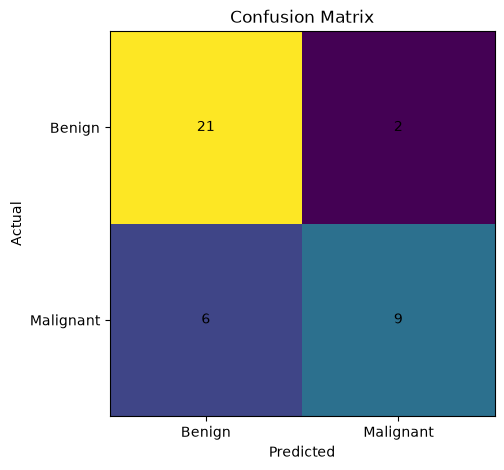

In [10]:
cm = confusion_matrix(
    true_labels,
    predicted_labels
)

plt.figure(figsize=(5, 5))
plt.imshow(cm)

plt.xticks(
    [0, 1],
    ["Benign", "Malignant"]
)
plt.yticks(
    [0, 1],
    ["Benign", "Malignant"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()


### 6.2 ROC Curve

The ROC curve shows classifier performance across different probability thresholds.


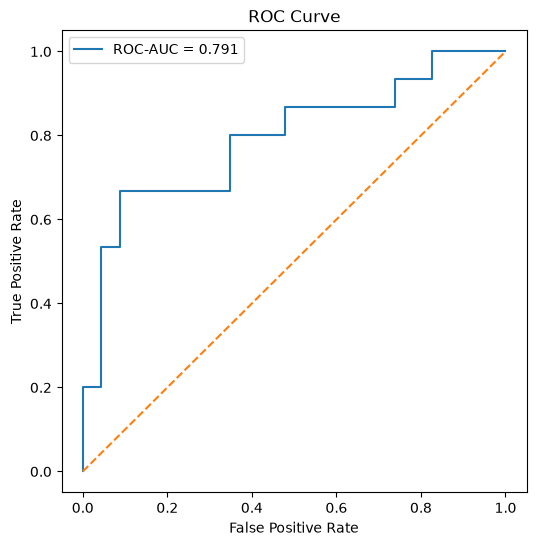

In [11]:
fpr, tpr, _ = roc_curve(
    true_labels,
    malignancy_probabilities
)

plt.figure(figsize=(6, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


## 7. Report-Generation Evaluation

The BrEaST dataset contains structured annotations rather than original free-text reports.

A reference report is therefore reconstructed using the same fields and formatting used during report-generator training.


In [12]:
def clean_value(value):
    if pd.isna(value):
        return "not available"

    value = str(value).strip()

    if value == "":
        return "not available"

    return value.replace("&", ", ")


def normalize_yes_no(value):
    value = clean_value(value).lower()

    if value == "yes":
        return "present"

    if value == "no":
        return "absent"

    return value


def normalize_posterior_features(value):
    value = clean_value(value)

    if value.lower() == "no":
        return "none"

    return value


def create_reference_report(row):
    return (
        "Findings: "
        f"Tissue composition: {clean_value(row['Tissue_composition'])}. "
        f"Shape: {clean_value(row['Shape'])}. "
        f"Margin: {clean_value(row['Margin'])}. "
        f"Echogenicity: {clean_value(row['Echogenicity'])}. "
        f"Posterior features: {normalize_posterior_features(row['Posterior_features'])}. "
        f"Halo: {normalize_yes_no(row['Halo'])}. "
        f"Calcifications: {normalize_yes_no(row['Calcifications'])}. "
        f"Skin thickening: {normalize_yes_no(row['Skin_thickening'])}. "
        f"Assessment: BI-RADS {clean_value(row['BIRADS'])}. "
    )


test_df["reference_report"] = test_df.apply(
    create_reference_report,
    axis=1
)


### 7.1 Generate Reports for the Test Set

Each test case is passed through the full system.


In [13]:
generated_reports = []
reference_reports = []

for _, row in test_df.iterrows():
    result = run_full_pipeline(
        image_path=(
            IMAGE_DIR / row["Image_filename"]
        ),
        age=row["Age"],
        tissue_composition=row[
            "Tissue_composition"
        ],
        signs=row["Signs"],
        symptoms=row["Symptoms"]
    )

    generated_text = (
        result["report"]
        .split("Final classification:")[0]
        .strip()
    )

    generated_reports.append(
        generated_text
    )

    reference_reports.append(
        row["reference_report"]
    )


### 7.2 BLEU, ROUGE-L, and METEOR

The report generator is evaluated using three text-overlap metrics:

- **BLEU** measures n-gram overlap between generated and reference reports.
- **ROUGE-L** measures similarity based on the longest common subsequence.
- **METEOR** considers token matching and linguistic similarity.


In [14]:
smoothing = SmoothingFunction().method1

bleu_scores = []
rouge_l_scores = []
meteor_scores = []

rouge = rouge_scorer.RougeScorer(
    ["rougeL"],
    use_stemmer=True
)

for reference, generated in zip(
    reference_reports,
    generated_reports
):
    reference_tokens = (
        reference.lower().split()
    )
    generated_tokens = (
        generated.lower().split()
    )

    bleu_scores.append(
        sentence_bleu(
            [reference_tokens],
            generated_tokens,
            smoothing_function=smoothing
        )
    )

    rouge_l_scores.append(
        rouge.score(
            reference,
            generated
        )["rougeL"].fmeasure
    )

    meteor_scores.append(
        meteor_score(
            [reference_tokens],
            generated_tokens
        )
    )

print("BLEU:", np.mean(bleu_scores))
print(
    "ROUGE-L:",
    np.mean(rouge_l_scores)
)
print(
    "METEOR:",
    np.mean(meteor_scores)
)


BLEU: 0.6330563173618039
ROUGE-L: 0.8505186547690566
METEOR: 0.8012786721007432


## 8. Error Analysis

Per-case classification and segmentation results are combined so that incorrect classifications and low-Dice segmentation cases can be inspected.


In [ ]:
results_df = pd.DataFrame(
    classification_results
)

seg_df = pd.DataFrame(
    segmentation_results
)

results_df = results_df.merge(
    seg_df,
    on="CaseID",
    how="left"
)

results_df[
    "Correct_classification"
] = (
    results_df["True"].str.lower()
    ==
    results_df["Predicted"].str.lower()
)

print("Misclassified cases:")
display(
    results_df[
        results_df[
            "Correct_classification"
        ] == False
    ]
)


Misclassified cases:


,CaseID,True,Predicted,Malignancy_probability,Dice,IoU,Correct_classification
3,201,benign,malignant,0.819441,0.905910,0.828002,False
8,133,malignant,benign,0.440166,0.813623,0.685804,False
17,228,malignant,benign,0.093540,0.541092,0.370889,False
21,89,malignant,benign,0.318982,0.645870,0.476964,False
22,114,malignant,benign,0.101598,0.909322,0.833722,False
25,117,malignant,benign,0.321513,0.716493,0.558230,False
27,193,benign,malignant,0.540995,0.455179,0.294649,False
35,211,malignant,benign,0.219942,0.922771,0.856616,False


In [23]:
# Number of lowest-Dice cases to visualise
NUM_CASES = 5

lowest_dice_cases = (
    seg_df
    .sort_values("Dice")
    .head(NUM_CASES)
)
print("\nLowest Dice cases:")
display(lowest_dice_cases)


Lowest Dice cases:


,CaseID,Dice,IoU
16,177,0.016461,0.008299
15,155,0.338254,0.203553
27,193,0.455179,0.294649
31,204,0.455361,0.294801
23,202,0.463444,0.301612


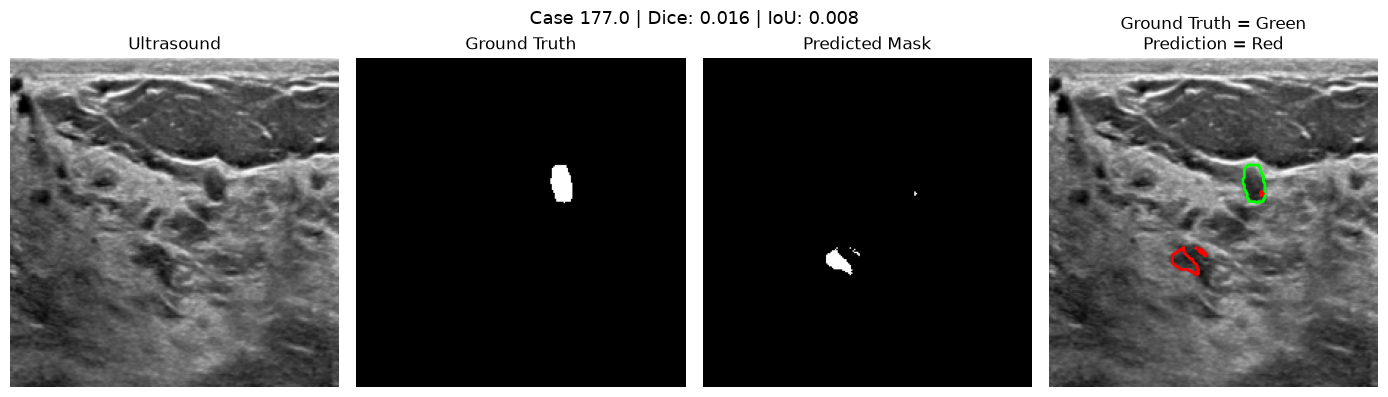

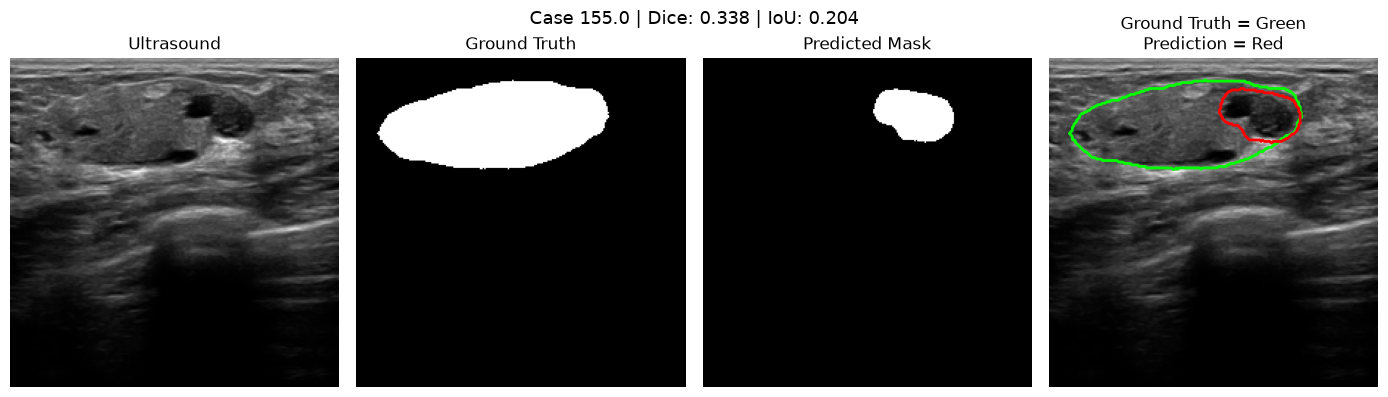

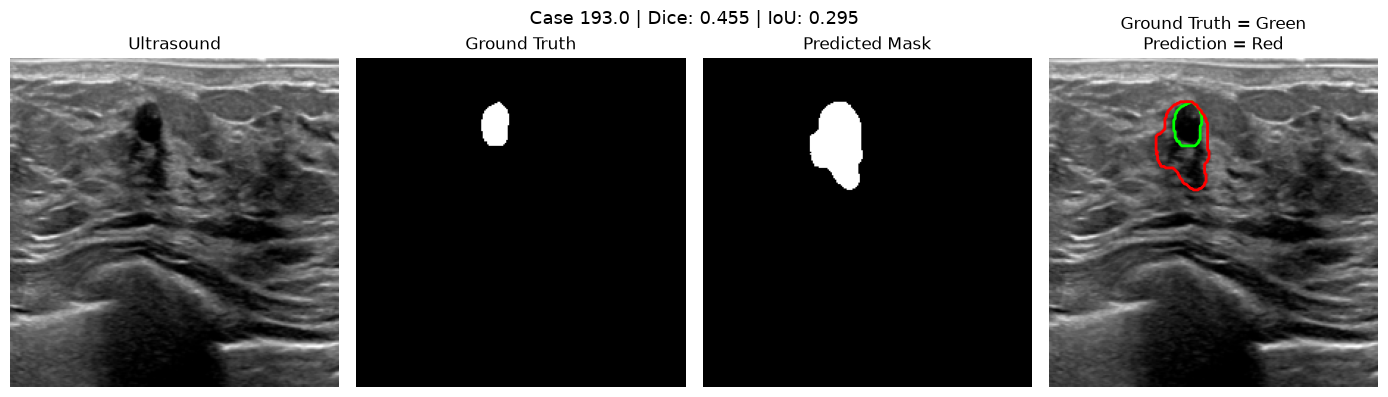

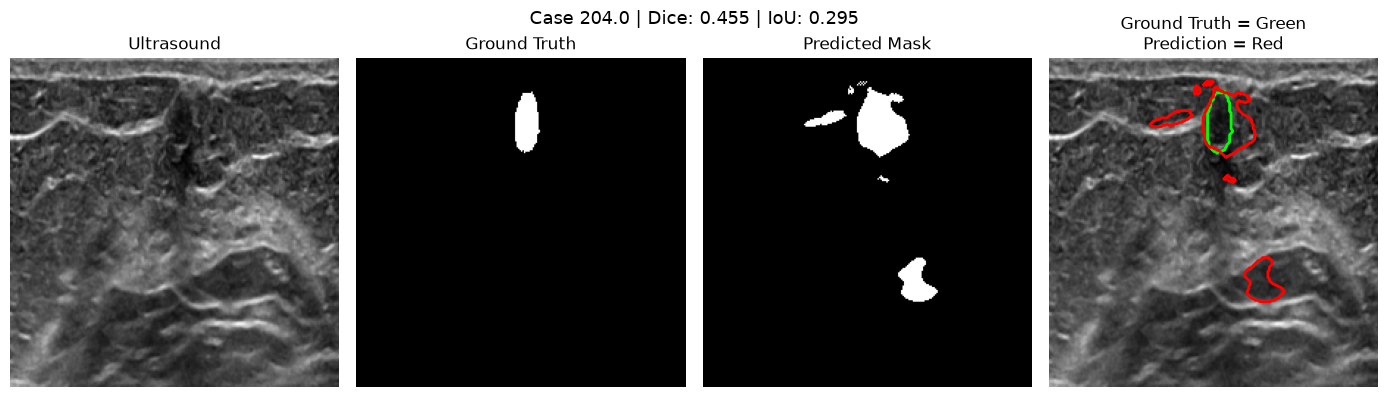

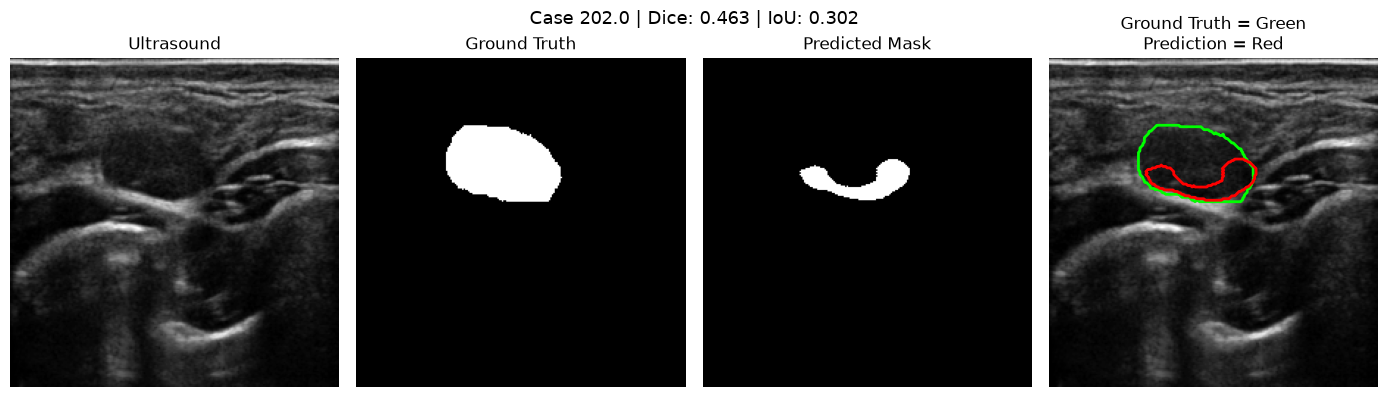

In [24]:
for _, case in lowest_dice_cases.iterrows():

    case_id = case["CaseID"]
    dice_score = case["Dice"]
    iou_score = case["IoU"]

    # Find the corresponding row in the test set
    row = test_df[
        test_df["CaseID"] == case_id
    ].iloc[0]

    # Load image and ground-truth mask
    image, ground_truth_mask = load_image_and_mask(row)

    image = image.to(device)

    # Generate predicted mask
    with torch.no_grad():
        logits = segmentation_model(image)

        predicted_mask = (
            torch.sigmoid(logits) >= 0.5
        ).float()

    # Convert tensors for plotting
    image_np = (
        image
        .squeeze()
        .cpu()
        .numpy()
    )

    ground_truth_np = (
        ground_truth_mask
        .squeeze()
        .cpu()
        .numpy()
    )

    predicted_np = (
        predicted_mask
        .squeeze()
        .cpu()
        .numpy()
    )

    # Plot
    plt.figure(figsize=(14, 4))

    # Original ultrasound image
    plt.subplot(1, 4, 1)
    plt.imshow(image_np, cmap="gray")
    plt.title("Ultrasound")
    plt.axis("off")

    # Ground-truth mask
    plt.subplot(1, 4, 2)
    plt.imshow(ground_truth_np, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    # Predicted mask
    plt.subplot(1, 4, 3)
    plt.imshow(predicted_np, cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    # Boundary comparison overlay
    plt.subplot(1, 4, 4)
    plt.imshow(image_np, cmap="gray")

    plt.contour(
        ground_truth_np,
        levels=[0.5],
        colors="lime",
        linewidths=2
    )

    plt.contour(
        predicted_np,
        levels=[0.5],
        colors="red",
        linewidths=2
    )

    plt.title(
        "Ground Truth = Green\n"
        "Prediction = Red"
    )
    plt.axis("off")

    plt.suptitle(
        f"Case {case_id} | "
        f"Dice: {dice_score:.3f} | "
        f"IoU: {iou_score:.3f}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()

## 9. Save the Final Evaluation Results

Three CSV files are created:

- `test_classification_results.csv` — classification result and segmentation scores for each test case
- `report_generation_results.csv` — reference/generated reports and text metrics
- `final_evaluation_summary.csv` — overall segmentation, classification, and report-generation metrics.


In [16]:
results_df.to_csv(
    OUTPUT_DIR /
    "test_classification_results.csv",
    index=False
)

report_results_df = pd.DataFrame({
    "Reference": reference_reports,
    "Generated": generated_reports,
    "BLEU": bleu_scores,
    "ROUGE_L": rouge_l_scores,
    "METEOR": meteor_scores
})

report_results_df.to_csv(
    OUTPUT_DIR /
    "report_generation_results.csv",
    index=False
)

summary = {
    "Segmentation Dice":
        np.mean(dice_scores),

    "Segmentation IoU":
        np.mean(iou_scores),

    "Classification Accuracy":
        accuracy,

    "Classification Precision":
        precision,

    "Classification Recall":
        recall,

    "Classification F1":
        f1,

    "Classification ROC-AUC":
        auc,

    "Report BLEU":
        np.mean(bleu_scores),

    "Report ROUGE-L":
        np.mean(rouge_l_scores),

    "Report METEOR":
        np.mean(meteor_scores)
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=[
        "Metric",
        "Score"
    ]
)

display(summary_df)

summary_df.to_csv(
    OUTPUT_DIR /
    "final_evaluation_summary.csv",
    index=False
)


,Metric,Score
0,Segmentation Dice,0.730014
1,Segmentation IoU,0.608553
2,Classification Accuracy,0.789474
3,Classification Precision,0.818182
4,Classification Recall,0.600000
5,Classification F1,0.692308
6,Classification ROC-AUC,0.791304
7,Report BLEU,0.633056
8,Report ROUGE-L,0.850519
9,Report METEOR,0.801279
